<a href="https://colab.research.google.com/github/shilohchiu/bird_id/blob/main/bird_call_CNN_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Set Up

In [31]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


In [32]:
import os

base = '/content/drive/MyDrive/Machine Learning Final Project'
DATA_DIR = os.path.join(base, 'data', 'Converted Spectograms')

print(os.path.exists(base), os.path.exists(DATA_DIR))

True True


In order to do classic CNN model training we need to make sure that each set of labeled data is in its own folder. The code below seperates out the data, you shouldn't need to run it more than once.

In [ ]:
import json
import os
import shutil
from collections import Counter

json_path = os.path.join(base, 'data', 'labels.json')
source_folder = os.path.join(base, DATA_DIR)
parent_folder = os.path.join(base, 'data', 'Organized_Birds')

with open(json_path, 'r', encoding='utf-8') as f:
    file_labels = json.load(f)

print(Counter(file_labels.values()))

copied, skipped = 0, []

for filename, label in file_labels.items():
    source_path = os.path.join(source_folder, filename)
    target_folder = os.path.join(parent_folder, str(label).strip().replace('/', '_'))

    if not os.path.isfile(source_path):
        skipped.append(filename)
        continue

    os.makedirs(target_folder, exist_ok=True)
    shutil.copy2(source_path, os.path.join(target_folder, filename))
    copied += 1

print(f'Copied {copied}, skipped {len(skipped)}')
if skipped:
    print('First few skipped:', skipped[:10])

Counter({'Dark-eyed Junco': 646, 'Northern House Wren': 535, 'Fox Sparrow': 429, 'Red Crossbill': 428, 'American Robin': 415, 'White-breasted Nuthatch': 392, 'American Crow': 385, 'Marsh Wren': 373, 'Red-winged Blackbird': 351, 'American Goldfinch': 349, 'Willet': 348, 'Redpoll': 341, "Brewer's Sparrow": 324, 'Blue-gray Gnatcatcher': 321, 'Summer Tanager': 306, 'House Finch': 303, 'Sedge Wren': 289, 'Song Sparrow': 289, 'Blue Jay': 288, 'Red-shouldered Hawk': 282, 'Chipping Sparrow': 280, 'Pacific Wren': 279, 'Nashville Warbler': 276, 'White-winged Crossbill': 276, 'Seaside Sparrow': 271, 'Purple Finch': 264, 'Carolina Wren': 259, 'Lark Sparrow': 255, 'Gray Catbird': 252, "Hutton's Vireo": 252, 'Ruby-crowned Kinglet': 251, 'Tufted Titmouse': 251, 'Purple Martin': 248, 'Cackling Goose': 247, 'Evening Grosbeak': 247, 'Northern Mockingbird': 245, "Botteri's Sparrow": 241, 'Dunlin': 240, 'Baltimore Oriole': 237, 'Hairy Woodpecker': 235, 'Canada Goose': 232, 'Northern Saw-whet Owl': 232, 'W

# Data exploration

In [ ]:
path_to_organized_birds = os.path.join(base, 'data', 'Organized_Birds')

In [ ]:
"""
Top ten samples
"""

sample_counts = {} # of form <species name : str> : <num samples/spectrograms : int>

for species in os.scandir(path_to_organized_birds):
  # print(os.path.join(path_to_organized_birds, species))

  if species.is_dir:
    sample_counts[species.name] = len([spectrogram for spectrogram in os.listdir(os.path.join(path_to_organized_birds, species))])

top_ten = sorted(sample_counts.items(), key=lambda item: item[1], reverse=True)[:10]

top_ten_species = []
for species, count in top_ten:
    print(f'{species}: {count}')
    top_ten_species.append(species)

**The ten classes with the most samples are**:
1. Dark-eyed Junco: 646
2. Northern House Wren: 535
3. Fox Sparrow: 429
4. Red Crossbill: 428
5. American Robin: 415
6. White-breasted Nuthatch: 392
7. Marsh Wren: 373
8. Red-winged Blackbird: 351
9. American Goldfinch: 349
10. Willet: 348                            

This is where we start to implement Tensor Flow Data

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

## Loading in dataset & training / val split

In [ ]:
BATCH_SIZE = 32
IMG_HEIGHT = 128
IMG_WIDTH = 87

In [ ]:
# create path splits for each of the top ten species. Later, if we decide to
# classify for the full dataset, we can amend this code
TOP_TEN_SPECIES = [
    "Dark-eyed Junco",
    "Northern House Wren",
    "Fox Sparrow",
    "Red Crossbill",
    "American Robin",
    "White-breasted Nuthatch",
    "Marsh Wren",
    "Red-winged Blackbird",
    "American Goldfinch",
    "Willet",
] # hard coded because code might take a long time to run

In [ ]:
import os
import json
import random as rnd

# splitting into training & val sets
# creates lists of paths rather than
# duplicating files

path_to_organized_birds = os.path.join(base, 'data', 'Organized_Birds')
val_split = 0.15 # 15% of data will be used for validationnn

# classes = sorted(species.name for species in os.scandir(path_to_organized_birds) if species.is_dir())
classes = sorted(TOP_TEN_SPECIES)
class_indices = {species : i for i, species in enumerate(classes)}

rng = rnd.Random(42)

train_paths = []
train_labels = []

val_paths = []
val_labels = []

for species in TOP_TEN_SPECIES:
  # NOTE: only look at the top ten species for now.
  # if we want to change this just change it to all the folders in the dir
  species_folder = os.path.join(path_to_organized_birds, species)

  # sort the png files only. idk if .ds_store is in there
  spectrograms = sorted(f for f in os.listdir(species_folder) if f.endswith('.png'))

  rng.shuffle(spectrograms)

  num_validation_files = round(len(spectrograms) * val_split)

  for f in spectrograms[:num_validation_files]:
      val_paths.append(os.path.join(species_folder, f))
      val_labels.append(class_indices[species])

  for f in spectrograms[num_validation_files:]:
      train_paths.append(os.path.join(species_folder, f))
      train_labels.append(class_indices[species])

# with open(os.path.join(base, 'data', 'class_names.json'), 'w') as f:
#     json.dump(classes, f, indent=2)

print(f'{len(TOP_TEN_SPECIES)} classes \ntrain={len(train_paths)} spectrograms, val={len(val_paths)} spectrograms')

In [ ]:
# train_ds = tf.keras.utils.image_dataset_from_directory(
#     DATA_DIR,
#     validation_split=0.2,
#     subset="training",
#     seed=123,
#     image_size=(IMG_HEIGHT, IMG_WIDTH),
#     batch_size=BATCH_SIZE,
#     color_mode="grayscale"
# )

# val_ds = tf.keras.utils.image_dataset_from_directory(
#     DATA_DIR,
#     validation_split=0.2,
#     subset="validation",
#     seed=123,
#     image_size=(IMG_HEIGHT, IMG_WIDTH),
#     batch_size=BATCH_SIZE,
#     color_mode="grayscale"
# )

In [ ]:
# making dataset functions

import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE # allows concurrent processing

def load_img(path, label):
  """
  returns a tuple of processed/loaded img w/ its label
  """
  img = tf.io.read_file(path) # opens path as raw bytes
  img = tf.io.decode_png(img, channels=1) # creates img tensor

  img = tf.image.resize(img, (IMG_HEIGHT, IMG_WIDTH), antialias=True)

  return tf.cast(img, tf.float32) / 255.0, label # scale pixel vals to 0, 1

def make_dataset(paths, labels, training : bool):
  """
  makes dataset by running load_img on every item
  """
  dataset = tf.data.Dataset.from_tensor_slices((paths, labels)) # associates each label w path
  if training:
      # only shuffle over eachepochfor training
      dataset = dataset.shuffle(len(paths), seed=42, reshuffle_each_iteration=True)

  # run load img on every pair
  return dataset.map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [ ]:
# make the training and validation datasets

training = make_dataset(train_paths,train_labels,training=True)
validation = make_dataset(val_paths,val_labels,training=False)

# print(training)

## Building the model

https://www.tensorflow.org/tutorials/images/cnn

In [ ]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))



compile model

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

history = model.fit(training, validation_data=validation,epochs = 2)

Epoch 1/2
114/114 ━━━━━━━━━━━━━━━━━━━━ 439s 4s/step - accuracy: 0.4883 - loss: 1.4242 - val_accuracy: 0.6854 - val_loss: 0.8733
Epoch 2/2
114/114 ━━━━━━━━━━━━━━━━━━━━ 53s 466ms/step - accuracy: 0.7681 - loss: 0.6545 - val_accuracy: 0.8341 - val_loss: 0.5139


ValueError: Unrecognized data type: x=['/content/drive/MyDrive/Machine Learning Final Project/data/Organized_Birds/Dark-eyed Junco/Dark-eyed Junco 10 Song (Slate-colored) US-NY_spectrogram_slice10.png', '/content/drive/MyDrive/Machine Learning Final Project/data/Organized_Birds/Dark-eyed Junco/Dark-eyed Junco 23 Song (White-winged) US-SD_spectrogram_slice17.png', '/content/drive/MyDrive/Machine Learning Final Project/data/Organized_Birds/Dark-eyed Junco/Dark-eyed Junco 14 Song (Oregon) US-WA_spectrogram_slice19.png', '/content/drive/MyDrive/Machine Learning Final Project/data/Organized_Birds/Dark-eyed Junco/Dark-eyed Junco 21 Song (White-winged) US-SD_spectrogram_slice31.png', '/content/drive/MyDrive/Machine Learning Final Project/data/Organized_Birds/Dark-eyed Junco/Dark-eyed Junco 14 Song (Oregon) US-WA_spectrogram_slice14.png', '/content/drive/MyDrive/Machine Learning Final Project/data/Organized_Birds/Dark-eyed Junco/Dark-eyed Junco 09 Juvenile calls US-NY_spectrogram_slice19.png',

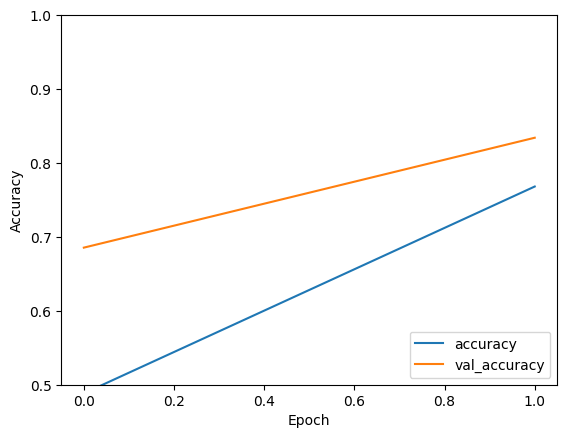

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(validation, verbose=2)
